# Робо-эдвайзер и инвестиционный советник: стоимость портфеля за 10 лет

Домашнее задание по теме «Финансовые рынки и инвестиции». Дата проверки тарифов: **01.11.2026**.

Начальный капитал — **1 000 000 ₽**. Сравниваются услуги Банка ВТБ (ПАО): **«Робот-советник» на тарифе «Мой онлайн», уровень «Базовый»**, и **Advisory Lite («Советник Лайт»), новое подключение после 27.11.2023**. Второй вариант — инвестиционное консультирование специалистами через чат, а не индивидуальное ДУ с выделенным управляющим. Это соответствует разрешённому в задании варианту «инвестиционный советник» и порогу капитала 1 млн ₽.

Модель сравнивает издержки при одинаковой валовой рыночной динамике. Она не воспроизводит реальные рекомендации ВТБ и не прогнозирует их доходность.

**Запуск:** Python 3.10+, библиотеки `numpy`, `pandas`, `matplotlib`. В Jupyter/Colab выполнить все ячейки сверху вниз. Результаты и графики уже сохранены. Расчёт 72 комбинаций на 2 000 траекториях занимает примерно минуту. Все параметры находятся в первой ячейке с кодом. Интернет для повторного расчёта не нужен.

## 1. Тарифы и источники

| Параметр | Робот | Советник Lite |
|---|---:|---:|
| Услуга консультирования | 0% | 2% годовых при портфеле до 30 млн ₽; 1% от 30 млн ₽ |
| Брокерская комиссия, каждая покупка и продажа | 0,25% | 0,25% |
| Биржевой сбор для заявки-тейкера на акции | 0,03% | 0,03% |
| Совокупная комиссия с оборота | 0,28% | 0,28% |
| Обслуживание / расчётные операции | 0 ₽ | 0 ₽ по базовому счёту; консультационная плата отдельно |
| Пополнение / рублёвый вывод на счёт в ВТБ | 0 ₽ | 0 ₽ |
| Комиссия за успех | 0% | 0%: Success Fee из регламента относится к Advisory Pro |

**Почему этот тариф:** обычный розничный клиент без премиального пакета, банковских льгот и специальных условий. Уровень «Базовый» фиксируется на весь расчёт. Обязательных платных банковских подписок в модели нет. Услуга Lite выбрана из-за порога 1 млн ₽ и отсутствия Success Fee. Это сравнение двух выбранных услуг, а не поиск самого дешёвого брокера. Робот приносит банку доход через плату за сделки; биржевой сбор является расходом инфраструктуры, а не платой за робота.

 
 

1. [ВТБ: тарифы «Мой онлайн», уровни клиента и биржевой сбор](https://www.vtb.ru/personal/investicii/tarify/).
2. [ВТБ: обслуживание, робот, пополнение и вывод](https://www.vtb.ru/personal/investicii/).
3. [ВТБ: раскрытие информации, бесплатность программы робота](https://www.vtb.ru/ir/disclosure/regulatory/).
4. [ВТБ: PDF, условия услуги Advisory Lite, с. 2](https://vtbrussia.ru/media-files/vtb.ru/sitepages/personal/investicii/tarify/moy_online_privilegiya.pdf). Использован блок самой услуги Lite, а не льготная ставка пакета «Привилегия».
5. [ВТБ: регламент 2026, раздел III тарифов, новое подключение Lite/Pro; раздел V — Success Fee только Pro](https://vtbrussia.ru/media-files/vtb.ru/sitepages/personal/investicii/documents/reglament/2026-02-27-reglament.pdf).
6. [ВТБ: приложение № 9, ежемесячный расчёт по средней стоимости активов](https://vtbrussia.ru/media-files/vtb.ru/sitepages/personal/investicii/documents/reglament/2026-02-27-prilogenie_9_k_reglamentu.pdf).
7. [ВТБ: правила консультирования, пп. 5.6–5.7](https://vtbrussia.ru/media-files/vtb.ru/sitepages/personal/investicii/documents/pravila-invest-consultirovaniya-actual.pdf).
8. [ФНС: шкала 13% / 15% и порог 2,4 млн ₽](https://www.nalog.gov.ru/rn51/promo/new2025/).
9. [ФНС: перенос убытков по биржевым ценным бумагам на следующие 10 лет](https://www.nalog.gov.ru/rn77/taxation/taxes/ndfl/nalog_vichet/nv_ubit/).

Теоретическая основа — раздел об автоматизированных консультантах из предоставленной лекции 7. Американские ориентиры 0,25% и 1% из лекции не подменяют российские тарифы. ЦФА из лекции 8 в рассматриваемый фондовый портфель не включены.

## 2. Допущения и расчёт

**Рыночный риск.** 5%, 10%, 15% — математическое ожидание простой годовой доходности до всех издержек. Волатильность 10% или 20% — её годовое стандартное отклонение. Это не фиксированный CAGR каждой траектории. Используется логнормальная модель:


$$
v^2 = \ln\left(1 + \frac{\sigma^2}{(1+\mu)^2}\right)
$$

$$
R_m = \exp\left(
\frac{\ln(1+\mu) - \frac{v^2}{2}}{12}
+ \frac{v}{\sqrt{12}} Z_m
\right) - 1
$$


За год такая модель даёт точно $E[R]=\mu$ и $SD[R]=\sigma$. Общие случайные числа и пары $Z,-Z$ используются для всех сравниваемых услуг и частот. Это уменьшает шум сравнения. Таблицы показывают среднее по 2 000 путям, а не гарантированный капитал.

**Портфель и оборот.** Используется синтетическая корзина ликвидных российских акций с одной модельной ценой, без дивидендов, купонов, фондов, валюты, плеча и бумаг ВТБ. Это упрощение для выделения стоимости услуг. При ребалансировке продаётся 20% текущей позиции и покупается эквивалентная рыночная экспозиция. Годовой двусторонний оборот от плановых ребалансировок составляет примерно 480%, 160% или 40% капитала при месячной, квартальной или годовой частоте. Это заданный параметр, не статистика ВТБ. В конце года 10 вместо очередной ребалансировки продаётся весь остаток, повторной покупки нет. Сравнение частот меняет одновременно частоту и годовой оборот. Ниже есть дополнительный контроль при одинаковом годовом обороте.

**Комиссии.** Покупка на бюджет $B$ даёт рыночную позицию $B/(1+c)$; продажа позиции $V$ даёт $V(1-c)$. Плата за советника начисляется ежемесячно как $m\,\overline{NAV}/12$, где средняя дневная стоимость приближена средним начала и конца месяца. Разница в календарных днях и банковский лаг списания не моделируются. При падении капитала услуга остаётся включённой; дополнительного взноса до 1 млн нет. Спред/проскальзывание приняты равными нулю для обоих вариантов, это явно исключённая рыночная издержка. Минимум биржевого сбора 0,02 ₽ не моделируется отдельно: сделки в расчёте намного крупнее. Лоты акций допускают дробление как вычислительное приближение.

**Налоги.** Обычный брокерский счёт резидента РФ, без ИИС и вычета за длительное владение; другие инвестиционные доходы отсутствуют. Порог 2,4 млн ₽ не расходуется на зарплату. Нереализованный рост не облагается. Себестоимость каждой покупки включает комиссии, при продаже применяется FIFO, сборы продажи уменьшают результат. Документированные расходы на инвестиционное консультирование отнесены к расходам профессионального участника, уменьшающим результат года — явное допущение налоговой модели (`DEDUCT_ADVISORY=True`, можно отключить). Правила и номинальный налоговый порог 2026 года неизменны на всём горизонте.


$$
T(B) = 0.13 \cdot \min\left(\max(B, 0), 2\,400\,000\right)
+ 0.15 \cdot \max\left(B - 2\,400\,000, 0\right)
$$


В режиме сальдирования положительные и отрицательные реализованные результаты суммируются за год, затем используется банк прошлых убытков в порядке возникновения; убытки старше 10 следующих лет исключаются. В режиме «Нет» отрицательные результаты и банк убытков игнорируются по условию ДЗ. В реальности годовое сальдирование брокером обычно автоматическое, а перенос прошлых убытков требует документов и декларации. Режим «Нет» — учебный контрфактический сценарий, а не предлагаемый налоговый режим. Механизм доступен обоим сервисам, робот не получает исключительной налоговой льготы.

**Самофинансирование.** Комиссии и НДФЛ оплачиваются из портфеля. Для этого продаётся необходимая часть позиции с учётом комиссии и возникающей прибыли/убытка. Годовой налог и продажа для его уплаты согласуются итерацией до погрешности менее 0,0001 ₽. Налог удерживается в конце модельного года; возврат/зачёт перенесённых убытков считается немедленным. Реальная задержка возврата не учитывается.

**Показатели.** Конечный капитал — деньги после полной продажи и всех налогов. Издержки — сумма фактически списанных комиссий и налогов за 10 лет, без дисконтирования. Процент издержек — отношение их среднего к среднему конечному капиталу. Он не равен снижению капитала относительно варианта без издержек: последнее включает потерянный сложный процент. Точка безубыточности — первый год устойчивого преимущества робота в средней стоимости после списаний; при месячном контроле показывается также первое преимущество по стоимости счёта.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace

INITIAL = 1_000_000.0
YEARS = 10
N_PATHS = 2000
SEED = 20261101
TURNOVER = 0.20  # доля портфеля, продаваемая при каждой ребалансировке
RATES = (0.05, 0.10, 0.15)
VOLS = (0.10, 0.20)
FREQUENCIES = {"Ежемесячно": 1, "Ежеквартально": 3, "Ежегодно": 12}
TAX_LIMIT = 2_400_000.0
TAX_LOW, TAX_HIGH = 0.13, 0.15
DEDUCT_ADVISORY = True

@dataclass(frozen=True)
class Tariff:
    name: str
    broker: float = 0.0025
    exchange: float = 0.0003
    management: float = 0.0
    management_large: float = 0.0
    large_threshold: float = 30_000_000.0
    fixed_monthly: float = 0.0
    withdrawal: float = 0.0

    @property
    def trade(self):
        return self.broker + self.exchange

ROBO = Tariff("Робот")
HUMAN = Tariff("Советник", management=0.02, management_large=0.01)

def tax_amount(base):
    base = np.maximum(base, 0.0)
    return TAX_LOW * np.minimum(base, TAX_LIMIT) + TAX_HIGH * np.maximum(base - TAX_LIMIT, 0)

def tax_base(gains, losses, expenses, carry, netting):
    """Вариант без сальдирования - условие задания, а не режим НК РФ."""
    before_carry = gains - expenses - (losses if netting else 0.0)
    return np.maximum(before_carry - (carry if netting else 0.0), 0.0)

def update_loss_bank(bank, year, annual_net, netting):
    # bank[:, j] - неиспользованный убыток года j+1; списываем старейший первым.
    bank = bank.copy()
    if not netting:
        bank[:] = 0
        return bank
    for j in range(bank.shape[1]):
        if year - (j + 1) > 10:
            bank[:, j] = 0
    need = np.maximum(annual_net, 0)
    for j in range(year - 1):
        use = np.minimum(bank[:, j], need)
        bank[:, j] -= use
        need -= use
    bank[:, year - 1] += np.maximum(-annual_net, 0)
    return bank

def make_factors(mu, sigma, z):
    # Калибровка именно простой годовой доходности: E[R]=mu, SD[R]=sigma.
    v2 = np.log1p((sigma / (1 + mu)) ** 2)
    log_drift = np.log1p(mu) - v2 / 2
    return np.exp(log_drift / 12 + np.sqrt(v2 / 12) * z)

def fifo_sale(qty, basis, price, sell_qty, commission):
    """Чистая выручка и прибыль/убыток по каждому FIFO-лоту. Без мутации."""
    before = np.cumsum(qty, axis=1) - qty
    sold = np.minimum(qty, np.maximum(sell_qty[:, None] - before, 0))
    gross = sold.sum(axis=1) * price
    fees = gross * commission
    pnl = sold * (price[:, None] * (1 - commission) - basis)
    return sold, gross - fees, fees, np.maximum(pnl, 0).sum(axis=1), np.maximum(-pnl, 0).sum(axis=1)


try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string(index=False) if hasattr(obj, 'to_string') else obj)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## 3. Движок: FIFO, оплата комиссий и годовой НДФЛ
Функция возвращает капитал по каждой траектории, отдельные комиссии и налоги, годовой журнал и ошибки сверки денежных потоков.

In [2]:
def simulate(factors, tariff, every=3, netting=True, turnover=TURNOVER,
             initial=INITIAL, deduct_advisory=DEDUCT_ADVISORY):
    """Самофинансируемый портфель: все комиссии и налоги платятся из него.

    Корзина акций представлена одной синтетической ценой; оборот при
    ребалансировке - продажа доли корзины и замена на эквивалентную экспозицию.
    Налоговый учет по FIFO, отдельная себестоимость каждой покупки.
    """
    n, months = factors.shape
    assert months % 12 == 0 and every in (1, 3, 12)
    years = months // 12
    slots = months // every + 1
    qty = np.zeros((n, slots))
    basis = np.zeros_like(qty)
    price = np.ones(n)
    c = tariff.trade
    invested = initial / (1 + c)
    qty[:, 0] = invested
    basis[:, 0] = 1 + c
    next_slot = 1
    fees_trade = np.full(n, initial - invested)
    fees_management = np.zeros(n)
    fees_fixed = np.zeros(n)
    taxes = np.zeros(n)
    gains = np.zeros(n)
    losses = np.zeros(n)
    expense_year = np.zeros(n)
    bank = np.zeros((n, years))
    history = np.zeros((n, years))
    monthly = np.zeros(months)
    annual_rows = []
    gross_pnl = np.zeros(n)
    max_tax_residual = 0.0
    max_reconciliation = 0.0
    final_cash = np.zeros(n)

    def sale(sell_qty, mutate=True):
        nonlocal qty, gains, losses, fees_trade
        view = slice(0, next_slot)
        result = fifo_sale(qty[:, view], basis[:, view], price, sell_qty, c)
        sold, proceeds, fees, gain, loss = result
        if mutate:
            qty[:, view] -= sold
            gains += gain
            losses += loss
            fees_trade += fees
        return proceeds, fees, gain, loss

    def sell_for_cash(amount):
        available = qty.sum(axis=1) * price * (1 - c)
        if np.any(amount > available + 1e-5):
            raise ValueError("Недостаточно средств для платежа: требуется отдельная модель банкротства")
        return sale(amount / (price * (1 - c)))

    for t in range(months):
        year = t // 12 + 1
        if t % 12 == 0:
            opening = qty.sum(axis=1) * price
            if t == 0:
                opening = np.full(n, initial)
            prev_trade = np.zeros(n) if t == 0 else fees_trade.copy()
            prev_mgmt = fees_management.copy()
            prev_fixed = fees_fixed.copy()
            prev_tax = taxes.copy()
            year_gross = np.zeros(n)
        before_market = qty.sum(axis=1) * price
        price *= factors[:, t]
        after_market = qty.sum(axis=1) * price
        this_gross = after_market - before_market
        gross_pnl += this_gross
        year_gross += this_gross

        # Средняя дневная СЧА приближена средним начала и конца месяца.
        average_nav = (before_market + after_market) / 2
        rate = np.where(average_nav >= tariff.large_threshold,
                        tariff.management_large, tariff.management)
        m_fee = average_nav * rate / 12
        fixed = np.full(n, tariff.fixed_monthly)
        if np.any(m_fee + fixed > 0):
            sell_for_cash(m_fee + fixed)
            fees_management += m_fee
            fees_fixed += fixed
            if deduct_advisory:
                expense_year += m_fee
            expense_year += fixed

        terminal = t == months - 1
        if terminal:
            final_cash = sale(qty.sum(axis=1))[0]
        elif (t + 1) % every == 0 and turnover > 0:
            proceeds = sale(qty.sum(axis=1) * turnover)[0]
            value = proceeds / (1 + c)
            fees_trade += proceeds - value
            qty[:, next_slot] = value / price
            basis[:, next_slot] = price * (1 + c)
            next_slot += 1

        if (t + 1) % 12 == 0:
            for j in range(year - 1):
                if year - (j + 1) > 10:
                    bank[:, j] = 0
            carry = bank.sum(axis=1)
            if not terminal:
                # Продажа на уплату НДФЛ тоже реализует результат в этом году.
                # Решаем T = налог(результат + результат продажи на сумму T).
                due = tax_amount(tax_base(gains, losses, expense_year, carry, netting))
                for _ in range(24):
                    _, _, extra_gain, extra_loss = sale(due / (price * (1 - c)), mutate=False)
                    new_due = tax_amount(tax_base(gains + extra_gain, losses + extra_loss,
                                                   expense_year, carry, netting))
                    if np.max(np.abs(new_due - due)) < 1e-7:
                        due = new_due
                        break
                    due = new_due
                sell_for_cash(due)
            else:
                due = tax_amount(tax_base(gains, losses, expense_year, carry, netting))
                if np.any(due > final_cash + 1e-5):
                    raise ValueError("НДФЛ превышает средства при закрытии")
                final_cash -= due
                withdrawal = final_cash * tariff.withdrawal
                final_cash -= withdrawal
                fees_fixed += withdrawal
            exact_due = tax_amount(tax_base(gains, losses, expense_year, carry, netting))
            max_tax_residual = max(max_tax_residual, np.max(np.abs(due - exact_due)))
            taxes += due
            net_result = gains - losses - expense_year
            bank = update_loss_bank(bank, year, net_result, netting)
            closing = final_cash if terminal else qty.sum(axis=1) * price
            history[:, year - 1] = closing
            paid_trade = fees_trade - prev_trade
            paid_mgmt = fees_management - prev_mgmt
            paid_fixed = fees_fixed - prev_fixed
            paid_tax = taxes - prev_tax
            residual = closing - (opening + year_gross - paid_trade - paid_mgmt - paid_fixed - paid_tax)
            max_reconciliation = max(max_reconciliation, np.max(np.abs(residual)))
            annual_rows.append({
                "Год": year, "Начало, ₽": opening.mean(), "Рыночный результат, ₽": year_gross.mean(),
                "Сделки, ₽": paid_trade.mean(), "Советник, ₽": paid_mgmt.mean(),
                "Прочие, ₽": paid_fixed.mean(), "НДФЛ, ₽": paid_tax.mean(), "Конец, ₽": closing.mean(),
                "Убытки к переносу, ₽": bank.sum(axis=1).mean(),
            })
            gains[:] = 0
            losses[:] = 0
            expense_year[:] = 0
        monthly[t] = (final_cash if terminal else qty.sum(axis=1) * price).mean()

    capital = final_cash
    fees = fees_trade + fees_management + fees_fixed
    costs = fees + taxes
    assert max_tax_residual < 1e-4, max_tax_residual
    assert max_reconciliation < 1e-4, max_reconciliation
    assert np.max(np.abs(capital - (initial + gross_pnl - costs))) < 1e-4
    assert np.min(qty) > -1e-8
    assert np.max(np.abs(qty)) < 1e-6
    return dict(capital=capital, fees=fees, trade_fees=fees_trade,
                management_fees=fees_management, taxes=taxes, costs=costs,
                history=history, monthly=monthly, audit=pd.DataFrame(annual_rows),
                tax_residual=max_tax_residual, reconciliation=max_reconciliation)

def summary_row(result, mu, sigma, frequency, netting, service):
    capital = result["capital"]
    return {
        "Доходность": mu, "Волатильность": sigma, "Частота": frequency,
        "Сальдирование": "Да" if netting else "Нет", "Сервис": service,
        "Капитал, ₽": capital.mean(), "Медиана, ₽": np.median(capital),
        "P10, ₽": np.quantile(capital, .10), "P90, ₽": np.quantile(capital, .90),
        "Комиссии, ₽": result["fees"].mean(), "НДФЛ, ₽": result["taxes"].mean(),
        "Издержки, ₽": result["costs"].mean(),
        "Издержки / капитал": result["costs"].mean() / capital.mean(),
        "P(капитал < 1 млн)": np.mean(capital < INITIAL),
    }

## 4. Проверки расчёта
Проверяются налоговая граница, FIFO, срок переноса убытков, аналитические случаи и совпадение при одинаковых тарифах. Каждая симуляция дополнительно сверяет движение капитала по каждому пути.

In [3]:
def run_tests():
    assert np.isclose(tax_amount(3_000_000), 402_000)
    assert np.isclose(tax_amount(2_400_000), 312_000)
    assert tax_amount(-100) == 0
    q = np.array([[10., 20.]])
    b = np.array([[100., 150.]])
    sold, proceeds, fee, gain, loss = fifo_sale(q, b, np.array([120.]), np.array([15.]), 0)
    assert np.allclose(sold, [[10, 5]]) and gain[0] == 200 and loss[0] == 150
    bank = np.zeros((1, 12)); bank[0, 0] = 100; bank[0, 1] = 70
    bank = update_loss_bank(bank, 12, np.array([50.]), True)
    assert bank[0, 0] == 0 and bank[0, 1] == 20
    assert tax_base(100, 80, 0, 10, True) == 10
    assert tax_base(100, 80, 0, 10, False) == 100
    factors = np.full((2, 120), 1.1 ** (1 / 12))
    free = Tariff('Проверка', broker=0, exchange=0)
    r = simulate(factors, free, turnover=0)
    expected = INITIAL + (INITIAL * 1.1 ** 10 - INITIAL) * .87
    assert np.allclose(r['capital'], expected)
    r = simulate(np.ones((2, 120)), ROBO, every=3)
    shrink = (1 - ROBO.trade) / (1 + ROBO.trade)
    expected = INITIAL * shrink * (1 - TURNOVER + TURNOVER * shrink) ** 39
    assert np.allclose(r['capital'], expected)
    assert np.allclose(r['taxes'], 0)
    r2 = simulate(factors, replace(ROBO, name='Советник без дополнительной платы'))
    r1 = simulate(factors, ROBO)
    assert np.allclose(r1['capital'], r2['capital'])
    # Убыток года 1 компенсируется прибылью года 2; без переноса налог выше.
    assert np.isclose(tax_amount(tax_base(150, 0, 0, 100, True)), 6.5)
    return 'Пройдено: шкала НДФЛ, FIFO, 10-летнее истечение убытков, перенос, формула без затрат, оборот и равные тарифы.'


print(run_tests())

Пройдено: шкала НДФЛ, FIFO, 10-летнее истечение убытков, перенос, формула без затрат, оборот и равные тарифы.


## 5. Расчёт всех сценариев
3 доходности × 2 волатильности × 3 частоты × 2 режима налога × 2 сервиса = 72 комбинации. Начальная покупка и финальная продажа включены.

In [4]:
rng = np.random.default_rng(SEED)
assert N_PATHS % 2 == 0
half = rng.standard_normal((N_PATHS // 2, YEARS * 12))
z = np.vstack([half, -half])
results, rows = {}, []
for mu in RATES:
    for sigma in VOLS:
        factors = make_factors(mu, sigma, z)
        for frequency, every in FREQUENCIES.items():
            for netting in (True, False):
                for tariff in (ROBO, HUMAN):
                    key = (mu, sigma, frequency, netting, tariff.name)
                    result = simulate(factors, tariff, every, netting)
                    results[key] = result
                    rows.append(summary_row(result, mu, sigma, frequency, netting, tariff.name))
summary = pd.DataFrame(rows)
print(f'Рассчитано {len(summary)} комбинации, по {N_PATHS:,} траекторий в каждой.')
print('Максимальная ошибка сверки, ₽:', max(r['reconciliation'] for r in results.values()))
print('Максимальная ошибка расчёта НДФЛ, ₽:', max(r['tax_residual'] for r in results.values()))

Рассчитано 72 комбинации, по 2,000 траекторий в каждой.
Максимальная ошибка сверки, ₽: 9.313225746154785e-09
Максимальная ошибка расчёта НДФЛ, ₽: 9.560608305037022e-09


## 6. Основные результаты
База: квартальная ребалансировка, сальдирование и перенос разрешены обоим сервисам. Суммы в рублях, округление только для вывода. В колонках доходности и волатильности указаны проценты.

In [5]:
base = summary[(summary['Частота'] == 'Ежеквартально') & (summary['Сальдирование'] == 'Да')].copy()
base_view = base[['Доходность','Волатильность','Сервис','Капитал, ₽','Комиссии, ₽','НДФЛ, ₽','Издержки, ₽','Издержки / капитал']].copy()
base_view['Доходность'] *= 100
base_view['Волатильность'] *= 100
base_view['Издержки / капитал'] *= 100
base_view = base_view.rename(columns={'Доходность':'μ, %','Волатильность':'σ, %','Издержки / капитал':'Издержки / капитал, %'})
display(base_view.round(1))

,"μ, %","σ, %",Сервис,"Капитал, ₽","Комиссии, ₽","НДФЛ, ₽","Издержки, ₽","Издержки / капитал, %"
4,5.0,10.0,Робот,1455678.0,60284.6,76477.8,136762.4,9.4
5,5.0,10.0,Советник,1215538.0,277045.9,45960.2,323006.1,26.6
16,5.0,20.0,Робот,1418650.5,59587.3,98965.7,158553.0,11.2
17,5.0,20.0,Советник,1180386.1,273365.4,70721.8,344087.2,29.2
28,10.0,10.0,Робот,2207000.2,76683.2,182237.9,258921.0,11.7
29,10.0,10.0,Советник,1848197.4,348958.7,129671.8,478630.5,25.9
40,10.0,20.0,Робот,2172658.0,76066.5,195298.5,271364.9,12.5
41,10.0,20.0,Советник,1814072.8,345514.5,145526.0,491040.5,27.1
52,15.0,10.0,Робот,3284532.4,97952.6,341774.9,439727.5,13.4
53,15.0,10.0,Советник,2749954.1,440152.1,262109.4,702261.5,25.5


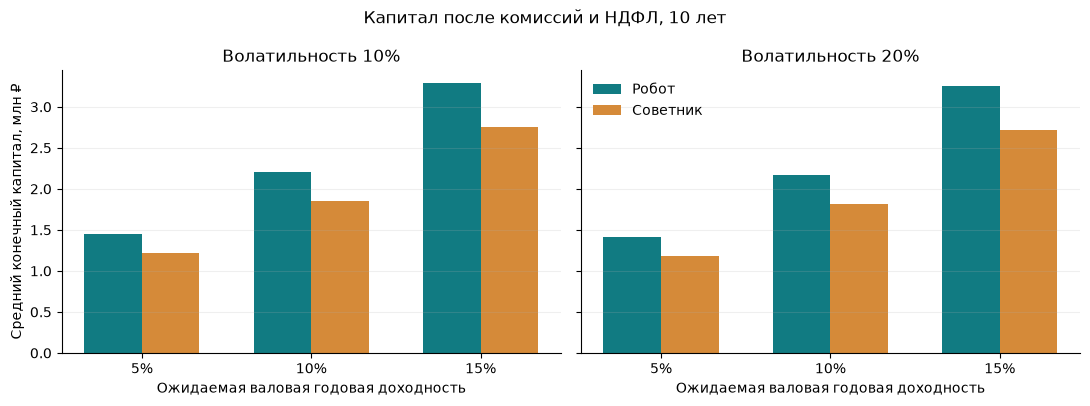

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), sharey=True)
for ax, sigma in zip(axes, VOLS):
    x = np.arange(len(RATES))
    for j, (service, color) in enumerate([('Робот', '#117B82'), ('Советник', '#D58A39')]):
        values = [results[(mu, sigma, 'Ежеквартально', True, service)]['capital'].mean() / 1e6 for mu in RATES]
        ax.bar(x + (j-.5)*.34, values, .34, label=service, color=color)
    ax.set_xticks(x, [f'{mu:.0%}' for mu in RATES])
    ax.set_title(f'Волатильность {sigma:.0%}')
    ax.set_xlabel('Ожидаемая валовая годовая доходность')
    ax.grid(axis='y', alpha=.2)
axes[0].set_ylabel('Средний конечный капитал, млн ₽')
axes[1].legend(frameon=False)
fig.suptitle('Капитал после комиссий и НДФЛ, 10 лет')
fig.tight_layout()
plt.show()

## 7. Точка безубыточности и неопределённость
В годах 1–9 используется стоимость счёта после фактически списанного годового налога, без гипотетической полной продажи. В году 10 портфель закрывается. Это относительная окупаемость меньших затрат, а не срок возврата начального миллиона. P10–P90 — диапазон исходов, не доверительный интервал среднего. Ошибка Монте-Карло считается по независимым парам Z и −Z.

In [7]:
comparison = []
for mu in RATES:
    for sigma in VOLS:
        r = results[(mu, sigma, 'Ежеквартально', True, 'Робот')]
        h = results[(mu, sigma, 'Ежеквартально', True, 'Советник')]
        annual_delta = (r['history'] - h['history']).mean(axis=0)
        breakeven = next((i+1 for i in range(YEARS) if np.all(annual_delta[i:] > 0)), None)
        month_delta = r['monthly'] - h['monthly']
        first_month = next((i+1 for i in range(YEARS*12) if np.all(month_delta[i:] > 0)), None)
        delta = r['capital'] - h['capital']
        pair_delta = (delta[:N_PATHS//2] + delta[N_PATHS//2:]) / 2
        se = pair_delta.std(ddof=1) / np.sqrt(N_PATHS//2)
        comparison.append({'μ, %':mu*100, 'σ, %':sigma*100, 'Преимущество, ₽':delta.mean(),
                           'Преимущество к советнику, %':delta.mean()/h['capital'].mean()*100,
                           'Первый год':breakeven, 'Первый месяц':first_month,
                           'SE преимущества, ₽':se, 'P(робот лучше), %':np.mean(delta>0)*100})
comparison = pd.DataFrame(comparison)
display(comparison.round(1))
risk = base[['Доходность','Волатильность','Сервис','Медиана, ₽','P10, ₽','P90, ₽','P(капитал < 1 млн)']].copy()
risk[['Доходность','Волатильность','P(капитал < 1 млн)']] *= 100
display(risk.round(1))

,"μ, %","σ, %","Преимущество, ₽","Преимущество к советнику, %",Первый год,Первый месяц,"SE преимущества, ₽","P(робот лучше), %"
0,5.0,10.0,240140.0,19.8,1,1,414.9,100.0
1,5.0,20.0,238264.4,20.2,1,1,1468.4,100.0
2,10.0,10.0,358802.8,19.4,1,1,558.6,100.0
3,10.0,20.0,358585.2,19.8,1,1,2110.4,100.0
4,15.0,10.0,534578.3,19.4,1,1,749.4,100.0
5,15.0,20.0,533529.7,19.6,1,1,2913.8,100.0


,Доходность,Волатильность,Сервис,"Медиана, ₽","P10, ₽","P90, ₽",P(капитал < 1 млн)
4,5.0,10.0,Робот,1406684.7,1002409.7,1973402.8,10.0
5,5.0,10.0,Советник,1176856.2,827529.4,1654198.8,26.1
16,5.0,20.0,Робот,1236913.9,607802.9,2453204.9,34.7
17,5.0,20.0,Советник,1030556.0,499124.7,2045856.8,47.9
28,10.0,10.0,Робот,2139842.1,1550489.5,2952860.9,0.2
29,10.0,10.0,Советник,1789901.6,1299383.3,2472444.1,1.2
40,10.0,20.0,Робот,1912156.1,1000231.7,3667920.0,10.0
41,10.0,20.0,Советник,1597169.9,828768.7,3066352.1,17.0
52,15.0,10.0,Робот,3188209.7,2343173.9,4353232.7,0.0
53,15.0,10.0,Советник,2670263.7,1962992.5,3641964.7,0.0


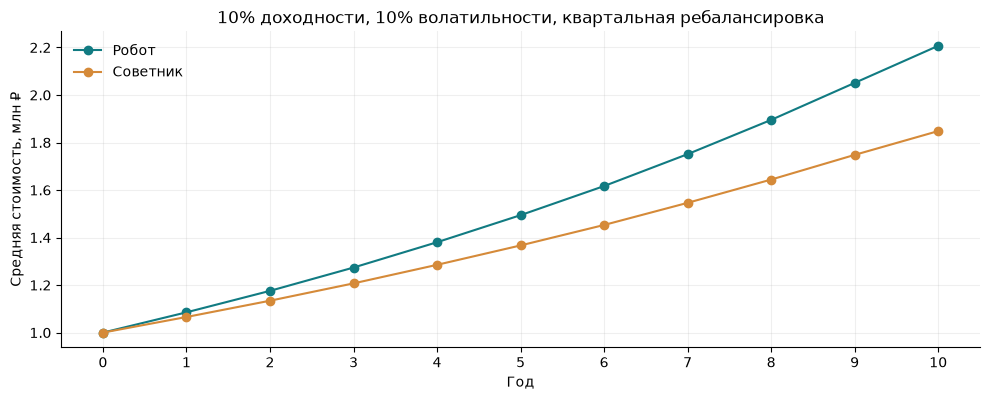

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.1))
for service, color in [('Робот','#117B82'), ('Советник','#D58A39')]:
    r = results[(.10, .10, 'Ежеквартально', True, service)]
    ax.plot(range(11), [INITIAL/1e6] + list(r['history'].mean(axis=0)/1e6), marker='o', label=service, color=color)
ax.set(xlabel='Год', ylabel='Средняя стоимость, млн ₽', title='10% доходности, 10% волатильности, квартальная ребалансировка')
ax.set_xticks(range(11)); ax.grid(alpha=.2); ax.legend(frameon=False)
fig.tight_layout(); plt.show()

## 8. Чувствительность к частоте и сальдированию
Для каждого сценария: капитал обоих сервисов и разность «робот − советник». «Нет» означает отказ обоих сервисов от сальдирования и переноса. Эффект механизма доступен обоим.

In [9]:
sensitivity = summary.pivot(index=['Доходность','Волатильность','Частота','Сальдирование'], columns='Сервис', values='Капитал, ₽').reset_index()
sensitivity['Преимущество, ₽'] = sensitivity['Робот'] - sensitivity['Советник']
breakeven_years, breakeven_months = [], []
for _, item in sensitivity.iterrows():
    key = (item['Доходность'], item['Волатильность'], item['Частота'], item['Сальдирование'] == 'Да')
    r, h = results[(*key, 'Робот')], results[(*key, 'Советник')]
    yd = (r['history'] - h['history']).mean(axis=0)
    mdiff = r['monthly'] - h['monthly']
    breakeven_years.append(next((i+1 for i in range(YEARS) if np.all(yd[i:] > 0)), None))
    breakeven_months.append(next((i+1 for i in range(YEARS*12) if np.all(mdiff[i:] > 0)), None))
sensitivity['Первый год преимущества'] = breakeven_years
sensitivity['Первый месяц преимущества'] = breakeven_months
sensitivity[['Доходность','Волатильность']] *= 100
display(sensitivity.round(0))
tax_effect = []
for sigma in VOLS:
    for frequency in FREQUENCIES:
        key = (.10, sigma, frequency)
        r_on, r_off = (results[(*key, enabled, 'Робот')]['capital'].mean() for enabled in (True,False))
        h_on, h_off = (results[(*key, enabled, 'Советник')]['capital'].mean() for enabled in (True,False))
        tax_effect.append({'σ, %':sigma*100, 'Частота':frequency,
            'Δ при сальдировании, ₽':r_on-h_on, 'Δ без сальдирования, ₽':r_off-h_off,
            'Польза сальдирования роботу, ₽':r_on-r_off,
            'Польза сальдирования советнику, ₽':h_on-h_off,
            'Δ если откажется только робот, ₽':r_off-h_on})
tax_effect = pd.DataFrame(tax_effect)
display(tax_effect.round(0))

Сервис,Доходность,Волатильность,Частота,Сальдирование,Робот,Советник,"Преимущество, ₽",Первый год преимущества,Первый месяц преимущества
0,5.0,10.0,Ежегодно,Да,1508424.0,1260261.0,248162.0,1,1
1,5.0,10.0,Ежегодно,Нет,1504118.0,1252806.0,251312.0,1,1
2,5.0,10.0,Ежеквартально,Да,1455678.0,1215538.0,240140.0,1,1
3,5.0,10.0,Ежеквартально,Нет,1432760.0,1195350.0,237410.0,1,1
4,5.0,10.0,Ежемесячно,Да,1340660.0,1117752.0,222908.0,1,1
5,5.0,10.0,Ежемесячно,Нет,1280006.0,1071646.0,208360.0,1,1
6,5.0,20.0,Ежегодно,Да,1480541.0,1232375.0,248166.0,1,1
7,5.0,20.0,Ежегодно,Нет,1468734.0,1219718.0,249016.0,1,1
8,5.0,20.0,Ежеквартально,Да,1418650.0,1180386.0,238264.0,1,1
9,5.0,20.0,Ежеквартально,Нет,1367288.0,1139155.0,228133.0,1,1


,"σ, %",Частота,"Δ при сальдировании, ₽","Δ без сальдирования, ₽","Польза сальдирования роботу, ₽","Польза сальдирования советнику, ₽","Δ если откажется только робот, ₽"
0,10.0,Ежемесячно,330245.0,320027.0,58312.0,48095.0,271932.0
1,10.0,Ежеквартально,358803.0,358642.0,14135.0,13974.0,344668.0
2,10.0,Ежегодно,376712.0,379049.0,1510.0,3847.0,375203.0
3,20.0,Ежемесячно,329399.0,299972.0,153249.0,123822.0,176150.0
4,20.0,Ежеквартально,358585.0,350308.0,56333.0,48056.0,302253.0
5,20.0,Ежегодно,376744.0,379322.0,9896.0,12475.0,366847.0


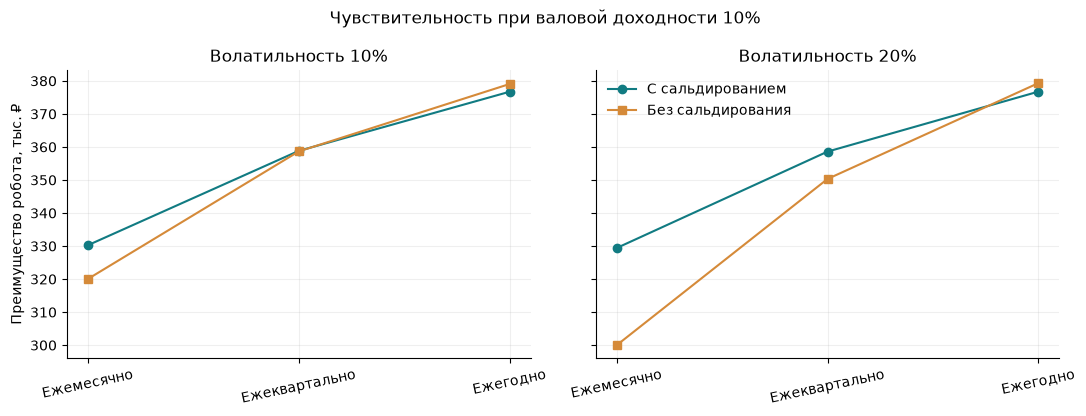

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11,4.2), sharey=True)
for ax, sigma in zip(axes, VOLS):
    for enabled, color, marker in [(True,'#117B82','o'),(False,'#D58A39','s')]:
        values = []
        for frequency in FREQUENCIES:
            r = results[(.10,sigma,frequency,enabled,'Робот')]['capital'].mean()
            h = results[(.10,sigma,frequency,enabled,'Советник')]['capital'].mean()
            values.append((r-h)/1000)
        ax.plot(list(FREQUENCIES), values, marker=marker, color=color, label='С сальдированием' if enabled else 'Без сальдирования')
    ax.set_title(f'Волатильность {sigma:.0%}')
    ax.tick_params(axis='x', labelrotation=12); ax.grid(alpha=.2)
axes[0].set_ylabel('Преимущество робота, тыс. ₽')
axes[1].legend(frameon=False)
fig.suptitle('Чувствительность при валовой доходности 10%')
fig.tight_layout(); plt.show()

## 9. Контроль при одинаковом годовом обороте
В основном сравнении оборот 20% за событие. Чтобы отделить этот эффект от частоты, ниже зафиксирована сумма плановых продаж 80% капитала в год: 6,67% ежемесячно, 20% ежеквартально, 80% ежегодно. Это дополнительная проверка при μ=10%, σ=10%, сальдировании. Из-за динамики капитала, финальной ликвидации и продаж на налоги фактические денежные обороты не обязаны совпадать.

In [11]:
equal_turnover = []
factors = make_factors(.10, .10, z)
for frequency, every in FREQUENCIES.items():
    per_event = .80 / (12/every)
    r = simulate(factors, ROBO, every, True, turnover=per_event)
    h = simulate(factors, HUMAN, every, True, turnover=per_event)
    equal_turnover.append({'Частота':frequency,'Продажа за событие, %':per_event*100,
                          'Робот, ₽':r['capital'].mean(),'Советник, ₽':h['capital'].mean(),
                          'Преимущество, ₽':(r['capital']-h['capital']).mean()})
equal_turnover = pd.DataFrame(equal_turnover)
display(equal_turnover.round(1))

,Частота,"Продажа за событие, %","Робот, ₽","Советник, ₽","Преимущество, ₽"
0,Ежемесячно,6.7,2207136.2,1848105.9,359030.3
1,Ежеквартально,20.0,2207000.2,1848197.4,358802.8
2,Ежегодно,80.0,2207082.4,1848973.8,358108.5


## 10. Годовой журнал и полная таблица издержек
Проверка: начало + рыночный результат − комиссии − НДФЛ = конец. В первом году учтена первоначальная покупка. В десятом — полная продажа. Все значения ниже — средние по тем же путям.

In [12]:
for service in ['Робот','Советник']:
    print(service)
    display(results[(.10,.10,'Ежеквартально',True,service)]['audit'].round(1))
all_costs = summary[['Доходность','Волатильность','Частота','Сальдирование','Сервис','Капитал, ₽','Комиссии, ₽','НДФЛ, ₽','Издержки, ₽','Издержки / капитал']].copy()
all_costs[['Доходность','Волатильность','Издержки / капитал']] *= 100
all_costs = all_costs.rename(columns={'Издержки / капитал':'Издержки / капитал, %'})
display(all_costs.round(1))
# При необходимости: summary.to_csv('all_scenarios.csv', index=False, encoding='utf-8-sig')

Робот


,Год,"Начало, ₽","Рыночный результат, ₽","Сделки, ₽","Советник, ₽","Прочие, ₽","НДФЛ, ₽","Конец, ₽","Убытки к переносу, ₽"
0,1,1000000.0,99487.3,7532.8,0.0,0.0,6619.7,1085334.8,5416.7
1,2,1085334.8,108641.6,5177.2,0.0,0.0,13085.3,1175713.9,6325.2
2,3,1175713.9,117756.3,5607.9,0.0,0.0,14075.2,1273787.1,6726.3
3,4,1273787.1,128015.8,6076.8,0.0,0.0,15349.7,1380376.4,7697.0
4,5,1380376.4,136920.5,6579.5,0.0,0.0,16399.3,1494318.0,7640.9
5,6,1494318.0,147272.8,7120.5,0.0,0.0,17643.7,1616826.7,7883.8
6,7,1616826.7,161191.2,7709.1,0.0,0.0,19173.7,1751135.1,8372.9
7,8,1751135.1,173244.9,8345.2,0.0,0.0,20754.3,1895280.5,8850.8
8,9,1895280.5,187111.9,9030.8,0.0,0.0,22340.9,2051020.7,9010.9
9,10,2051020.7,206279.0,13503.4,0.0,0.0,36796.1,2207000.2,12591.7


Советник


,Год,"Начало, ₽","Рыночный результат, ₽","Сделки, ₽","Советник, ₽","Прочие, ₽","НДФЛ, ₽","Конец, ₽","Убытки к переносу, ₽"
0,1,1000000.0,98567.4,7526.1,20696.8,0.0,4607.8,1065736.8,10611.6
1,2,1065736.8,105693.3,5074.6,22121.9,0.0,10035.4,1134198.2,12091.1
2,3,1134198.2,112549.0,5400.3,23542.6,0.0,10607.9,1207196.4,13275.2
3,4,1207196.4,120204.0,5748.7,25061.6,0.0,11332.8,1285257.3,14651.1
4,5,1285257.3,126297.2,6115.2,26663.9,0.0,11884.5,1366890.9,15355.1
5,6,1366890.9,133464.4,6501.6,28353.4,0.0,12506.2,1452994.1,16124.3
6,7,1452994.1,143521.3,6915.2,30153.3,0.0,13270.2,1546176.7,16399.3
7,8,1546176.7,151542.9,7355.0,32072.1,0.0,14161.7,1644130.7,17021.7
8,9,1644130.7,160804.8,7819.9,34101.1,0.0,15001.4,1748013.0,17749.1
9,10,1748013.0,174183.6,11442.7,36292.8,0.0,26263.7,1848197.4,19606.0


,Доходность,Волатильность,Частота,Сальдирование,Сервис,"Капитал, ₽","Комиссии, ₽","НДФЛ, ₽","Издержки, ₽","Издержки / капитал, %"
0,5.0,10.0,Ежемесячно,Да,Робот,1340660.3,161640.8,63325.4,224966.2,16.8
1,5.0,10.0,Ежемесячно,Да,Советник,1117752.5,359302.3,37495.0,396797.4,35.5
2,5.0,10.0,Ежемесячно,Нет,Робот,1280006.2,158670.9,116033.2,274704.1,21.5
3,5.0,10.0,Ежемесячно,Нет,Советник,1071645.8,353604.5,80977.5,434582.0,40.6
4,5.0,10.0,Ежеквартально,Да,Робот,1455678.0,60284.6,76477.8,136762.4,9.4
...,...,...,...,...,...,...,...,...,...,...
67,15.0,20.0,Ежеквартально,Нет,Советник,2673099.8,434298.4,301501.5,735799.9,27.5
68,15.0,20.0,Ежегодно,Да,Робот,3426238.4,33801.3,368421.5,402222.8,11.7
69,15.0,20.0,Ежегодно,Да,Советник,2858897.4,396326.3,282840.0,679166.3,23.8
70,15.0,20.0,Ежегодно,Нет,Робот,3419310.5,33784.8,373531.0,407315.8,11.9


## 11. Выводы

1. При одинаковой валовой доходности и риске дополнительная плата за консультации снижает конечный капитал. В выбранной модели робот имеет преимущество уже в первом году; месячный контроль показывает его после первого начисления платы советнику. Здесь нет разового входного платежа робота, который сначала надо окупать.
2. Рост валовой доходности увеличивает абсолютную разницу: сэкономленные комиссии продолжают приносить доход. Номинальная сумма списанных затрат меньше полной потери будущего капитала из-за издержек.
3. Частая ребалансировка при фиксированных 20% за событие увеличивает оборот, комиссии и число реализаций налогового результата. Из сравнения нельзя заключить, что частота сама по себе всегда вредна: для этого нужен контроль оборота и эффектов самой инвестиционной стратегии.
4. Сальдирование улучшает результат обоих сервисов. При большей волатильности появляется больше возможностей зачесть убытки, но одновременно расширяется разброс конечного капитала. Размер налогового эффекта зависит от порядка доходностей и реализованных лотов.
5. Вывод о меньших затратах не доказывает превосходство качества рекомендаций робота. Советник может иметь ценность за счёт индивидуальных решений и дисциплины. Дополнительная доходность советника в расчёт не заложена.

